# 02 baselines

three baselines: naive (last week's value), 28-day average, and full history average.

tested on 25 weekly forecasts (7 days ahead, every monday from 2015-02-02 to 2015-07-20) for all 1,115 stores.

## Set-Up (Imports and Loading Data)

In [10]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append('../src')

from load_clean_data import load_clean_data
from backtest import get_cutoffs, split_data_by_cutoff, run_backtest
from baselines import add_window_avg_baseline, add_all_baselines
from evaluation import evaluate_forecast, score_forecasts

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
df = load_clean_data()

assert df['Store'].is_monotonic_increasing, "Stores should be in order."
assert df.groupby('Store')['Date'].apply(lambda s: s.is_monotonic_increasing).all(), "Dates should be in order within each store."

df.shape

(1017209, 18)

## Single Cutoff + Single Store

looking at one forecast before running all 25. cutoff is 2015-02-02, so the models only see data before that date and forecast the 7 days from it. 

store 1 is shown as an example.

In [12]:
CUTOFF_DATE = '2015-02-02'

train, test = split_data_by_cutoff(df, CUTOFF_DATE, 7)

assert len(test) == test['Store'].nunique() * 7, "Every store should have 7 rows in the test week."

train.shape, test.shape

((816509, 18), (7805, 18))

In [13]:
results = add_all_baselines(train, test, CUTOFF_DATE)
    
store_1_results = results[results['Store'] == 1]

store_1_results_table = store_1_results[['Date', 'DayOfWeek', 'Sales', 'naive_baseline', 'avg_28d_baseline', 'avg_all_baseline']]

store_1_results_table.style.hide(axis='index').format(precision=0)

Date,DayOfWeek,Sales,naive_baseline,avg_28d_baseline,avg_all_baseline
2015-02-02 00:00:00,1,6038,4781,5022,5054
2015-02-03 00:00:00,2,4901,4806,4496,4691
2015-02-04 00:00:00,3,4672,4310,4236,4468
2015-02-05 00:00:00,4,4394,5171,4168,4123
2015-02-06 00:00:00,5,5022,5577,4330,4634
2015-02-07 00:00:00,6,4663,5363,5014,5004
2015-02-08 00:00:00,7,0,0,0,0


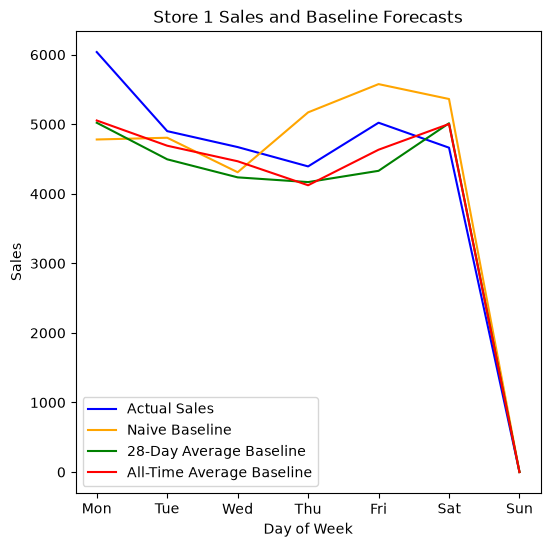

In [ ]:
plt.figure(figsize=(6, 6))

plt.plot(store_1_results['DayOfWeek'], store_1_results['Sales'], label='Actual Sales', color='blue')
plt.plot(store_1_results['DayOfWeek'], store_1_results['naive_baseline'], label='Naive Baseline', color='orange')
plt.plot(store_1_results['DayOfWeek'], store_1_results['avg_28d_baseline'], label='28-Day Average Baseline', color='green')
plt.plot(store_1_results['DayOfWeek'], store_1_results['avg_all_baseline'], label='Full History Average Baseline', color='red')

plt.title('Store 1 Sales and Baseline Forecasts')

plt.xticks(range(1, 8), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.xlabel('Day of Week')

plt.ylabel('Sales')

plt.legend()

plt.show()

what the chart shows:
- sunday is 0 for every forecast, because the store is closed on sundays
- naive just repeats last week, so it follows last week's pattern (high thursday to saturday) and overshoots
- the 28 day and full history averages are smoother and closer to the usual level for each weekday
- all three underestimate monday (6038 actual). the baselines only use past weekday averages, so they can't pick up a one-off jump like this

In [15]:
promo_check = store_1_results[['Date', 'DayOfWeek', 'Sales', 'Promo']]

promo_check.style.hide(axis='index').format(precision=0)

Date,DayOfWeek,Sales,Promo
2015-02-02 00:00:00,1,6038,1
2015-02-03 00:00:00,2,4901,1
2015-02-04 00:00:00,3,4672,1
2015-02-05 00:00:00,4,4394,1
2015-02-06 00:00:00,5,5022,1
2015-02-07 00:00:00,6,4663,0
2015-02-08 00:00:00,7,0,0


## Cutoffs and Backtest

25 weekly cutoffs, all mondays, from 2015-02-02 to 2015-07-20. 

each one forecasts the next 7 days for every store, giving 25 x 1,115 x 7 = 195,125 forecast rows.

In [16]:
cutoffs = get_cutoffs(df['Date'].max(), 7)

assert len(cutoffs) == 25, "There should be 25 cutoffs for a 7-day backtest."
assert (cutoffs.day_of_week == 0).all(), "All cutoffs should be on a Monday."

In [17]:
bt = run_backtest(df, cutoffs, 7, add_all_baselines)

assert len(bt) == 25 * df['Store'].nunique() * 7, "Backtest results should have the correct number of rows."

## Scoring the Backtest

errors from all 195,125 rows are pooled together before scoring, rather than averaging a score per store. 

this means big stores count for more.

In [ ]:
save_scores = True

baselines = ['naive_baseline', 'avg_28d_baseline', 'avg_all_baseline']

scores = score_forecasts(bt, baselines)

if save_scores:
    scores.to_csv('../results/baseline_scores.csv', index=False)

model_names = {
    'naive_baseline': 'Naive Baseline',
    'avg_28d_baseline': '28-Day Average Baseline',
    'avg_all_baseline': 'Full History Average Baseline'
}

relabelled_scores = scores.copy()

relabelled_scores['Model'] = relabelled_scores['Model'].replace(model_names)

relabelled_scores.sort_values(by='WAPE').style.hide(axis='index').format({ 'WAPE': '{:.2f}%' }, precision=2)

Model,RMSE,MAE,WAPE
Full History Average Baseline,2029.48,1261.49,21.53%
28-Day Average Baseline,2127.55,1326.10,22.63%
Naive Baseline,3206.68,2112.59,36.06%


finding: a longer memory gives a lower error (36.06%, then 22.63%, then 21.53%). the full history average is the number the models have to beat, at about 21.5% WAPE.

caveat: every forecast is 7 days ahead from a monday, so this says nothing about longer horizons.

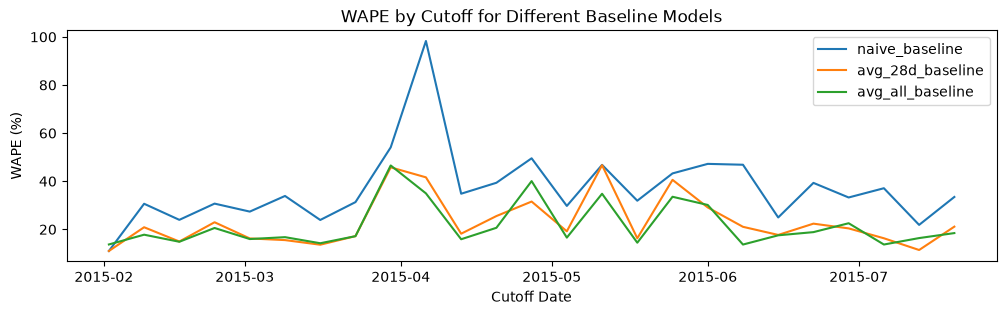

In [ ]:
scores_by_cutoff = score_forecasts(bt, baselines, by='cutoff')

pivotted = scores_by_cutoff.pivot(index='cutoff', columns='Model', values='WAPE')

plt.figure(figsize=(12, 3))

for model in baselines:
    plt.plot(pivotted.index, pivotted[model], label=model_names[model])

plt.title('WAPE by Cutoff for Different Baseline Models')
plt.xlabel('Cutoff Date')
plt.ylabel('WAPE (%)')
plt.legend()

plt.show()

finding: all three baselines spike in the same weeks, around the 30 mar and 6 apr cutoffs. this is probably Easter, but i haven't checked the holiday flags yet.